# 🏠 Real Estate Housing Price Prediction
## Ridge & Lasso Regression — California Housing Dataset

**Goal:** Predict median house values using OLS, Ridge (L2), and Lasso (L1) regression.  
**Techniques:** Feature engineering, missing value imputation, multicollinearity handling, GridSearchCV hyperparameter tuning, residual analysis.

---

## 📦 1. Import Libraries

In [1]:
from pathlib import Path

WORKING_DIRECTORY = Path.cwd().resolve()
PROJECT_DIRECTORY_CANDIDATES = []
for parent in (WORKING_DIRECTORY, *WORKING_DIRECTORY.parents):
    PROJECT_DIRECTORY_CANDIDATES.extend(
        [
            parent,
            parent / "Task2_RealEstate_HousingPricePrediction",
            parent / "task-2-california-housing-price-prediction",
            parent / "datheon-machine-learning-internship" / "task-2-california-housing-price-prediction",
        ]
    )
PROJECT_DIR = next(
    (candidate for candidate in PROJECT_DIRECTORY_CANDIDATES if (candidate / "housing.csv").is_file()),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError(
        "Could not locate housing.csv. Run this notebook from either Task 2 project folder."
    )

CSV_PATH = PROJECT_DIR / "housing.csv"
OUTPUT_DIR = PROJECT_DIR / "screenshots"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Project directory: {PROJECT_DIR}")
print(f"Generated plots will be saved in: {OUTPUT_DIR}")

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy import stats

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Set global plot style
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

RANDOM_STATE = 42
print('✅ Libraries imported successfully!')

Project directory: C:\Users\rainc\Downloads\Projects(intern)\Projects(intern)\Datheon\datheon-machine-learning-internship\task-2-california-housing-price-prediction
Generated plots will be saved in: C:\Users\rainc\Downloads\Projects(intern)\Projects(intern)\Datheon\datheon-machine-learning-internship\task-2-california-housing-price-prediction\screenshots
✅ Libraries imported successfully!


## 📂 2. Load the California Housing Dataset

In [2]:
df = pd.read_csv(CSV_PATH)
print(f'Dataset shape: {df.shape}')
df.head()

Dataset shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [3]:
print('\n📊 Dataset Info:')
df.info()
print('\n📈 Descriptive Statistics:')
df.describe().T.style.background_gradient(cmap='YlOrRd')


📊 Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.7 MB

📈 Descriptive Statistics:


,count,mean,std,min,25%,50%,75%,max
longitude,20640.000000,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
latitude,20640.000000,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
housing_median_age,20640.000000,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
total_rooms,20640.000000,2635.763081,2181.615252,2.000000,1447.750000,2127.000000,3148.000000,39320.000000
total_bedrooms,20433.000000,537.870553,421.385070,1.000000,296.000000,435.000000,647.000000,6445.000000
population,20640.000000,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
households,20640.000000,499.539680,382.329753,1.000000,280.000000,409.000000,605.000000,6082.000000
median_income,20640.000000,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
median_house_value,20640.000000,206855.816909,115395.615874,14999.000000,119600.000000,179700.000000,264725.000000,500001.000000


## 🔍 3. Exploratory Data Analysis (EDA)

Missing Values:
                 Missing Count  Missing %
total_bedrooms            207        1.0


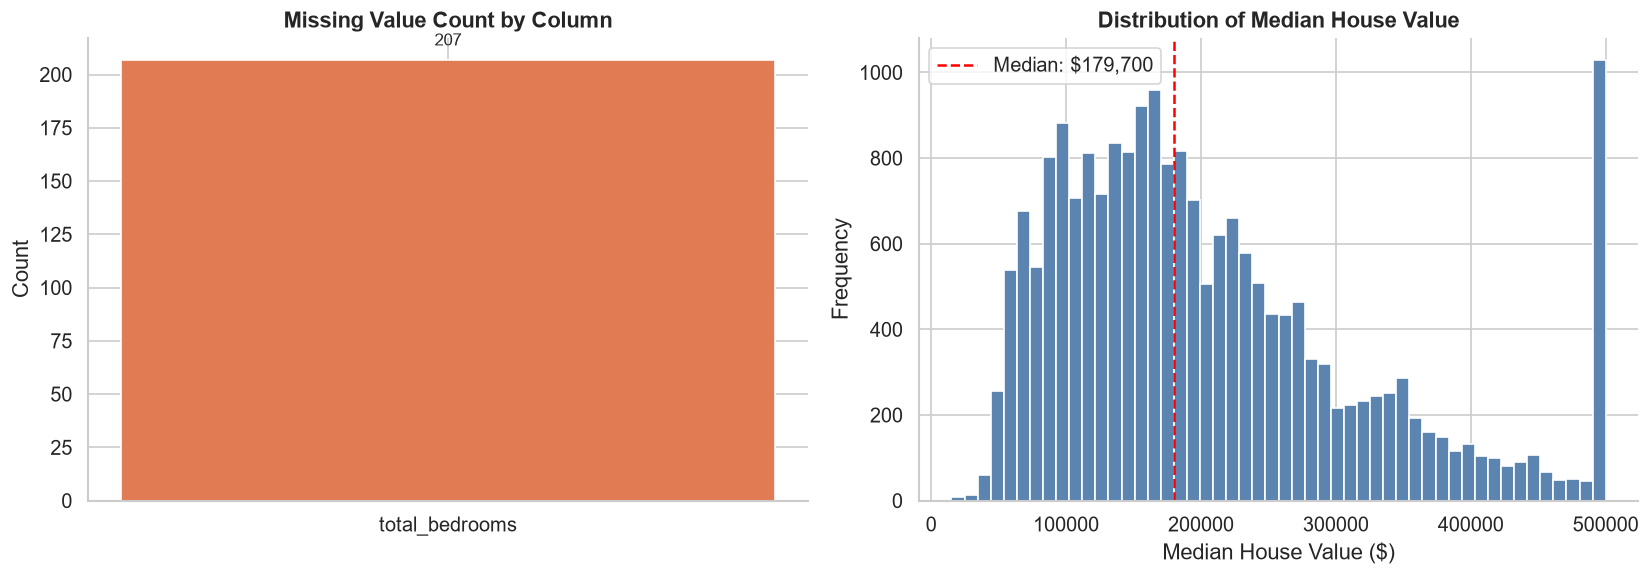

In [4]:
# ── Missing Value Analysis ──────────────────────────────────────────────────
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
missing_df = missing_df[missing_df['Missing Count'] > 0]
print('Missing Values:\n', missing_df)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Missing value bar chart
axes[0].bar(missing_df.index, missing_df['Missing Count'], color='#E07B54', edgecolor='white')
axes[0].set_title('Missing Value Count by Column', fontweight='bold')
axes[0].set_ylabel('Count')
for bar in axes[0].patches:
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                 str(int(bar.get_height())), ha='center', va='bottom', fontsize=10)

# Target distribution
axes[1].hist(df['median_house_value'], bins=50, color='#5B84B1', edgecolor='white')
axes[1].axvline(df['median_house_value'].median(), color='red', linestyle='--', label=f"Median: ${df['median_house_value'].median():,.0f}")
axes[1].set_title('Distribution of Median House Value', fontweight='bold')
axes[1].set_xlabel('Median House Value ($)')
axes[1].set_ylabel('Frequency')
axes[1].legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'eda_missing_target.png', bbox_inches='tight')
plt.show()

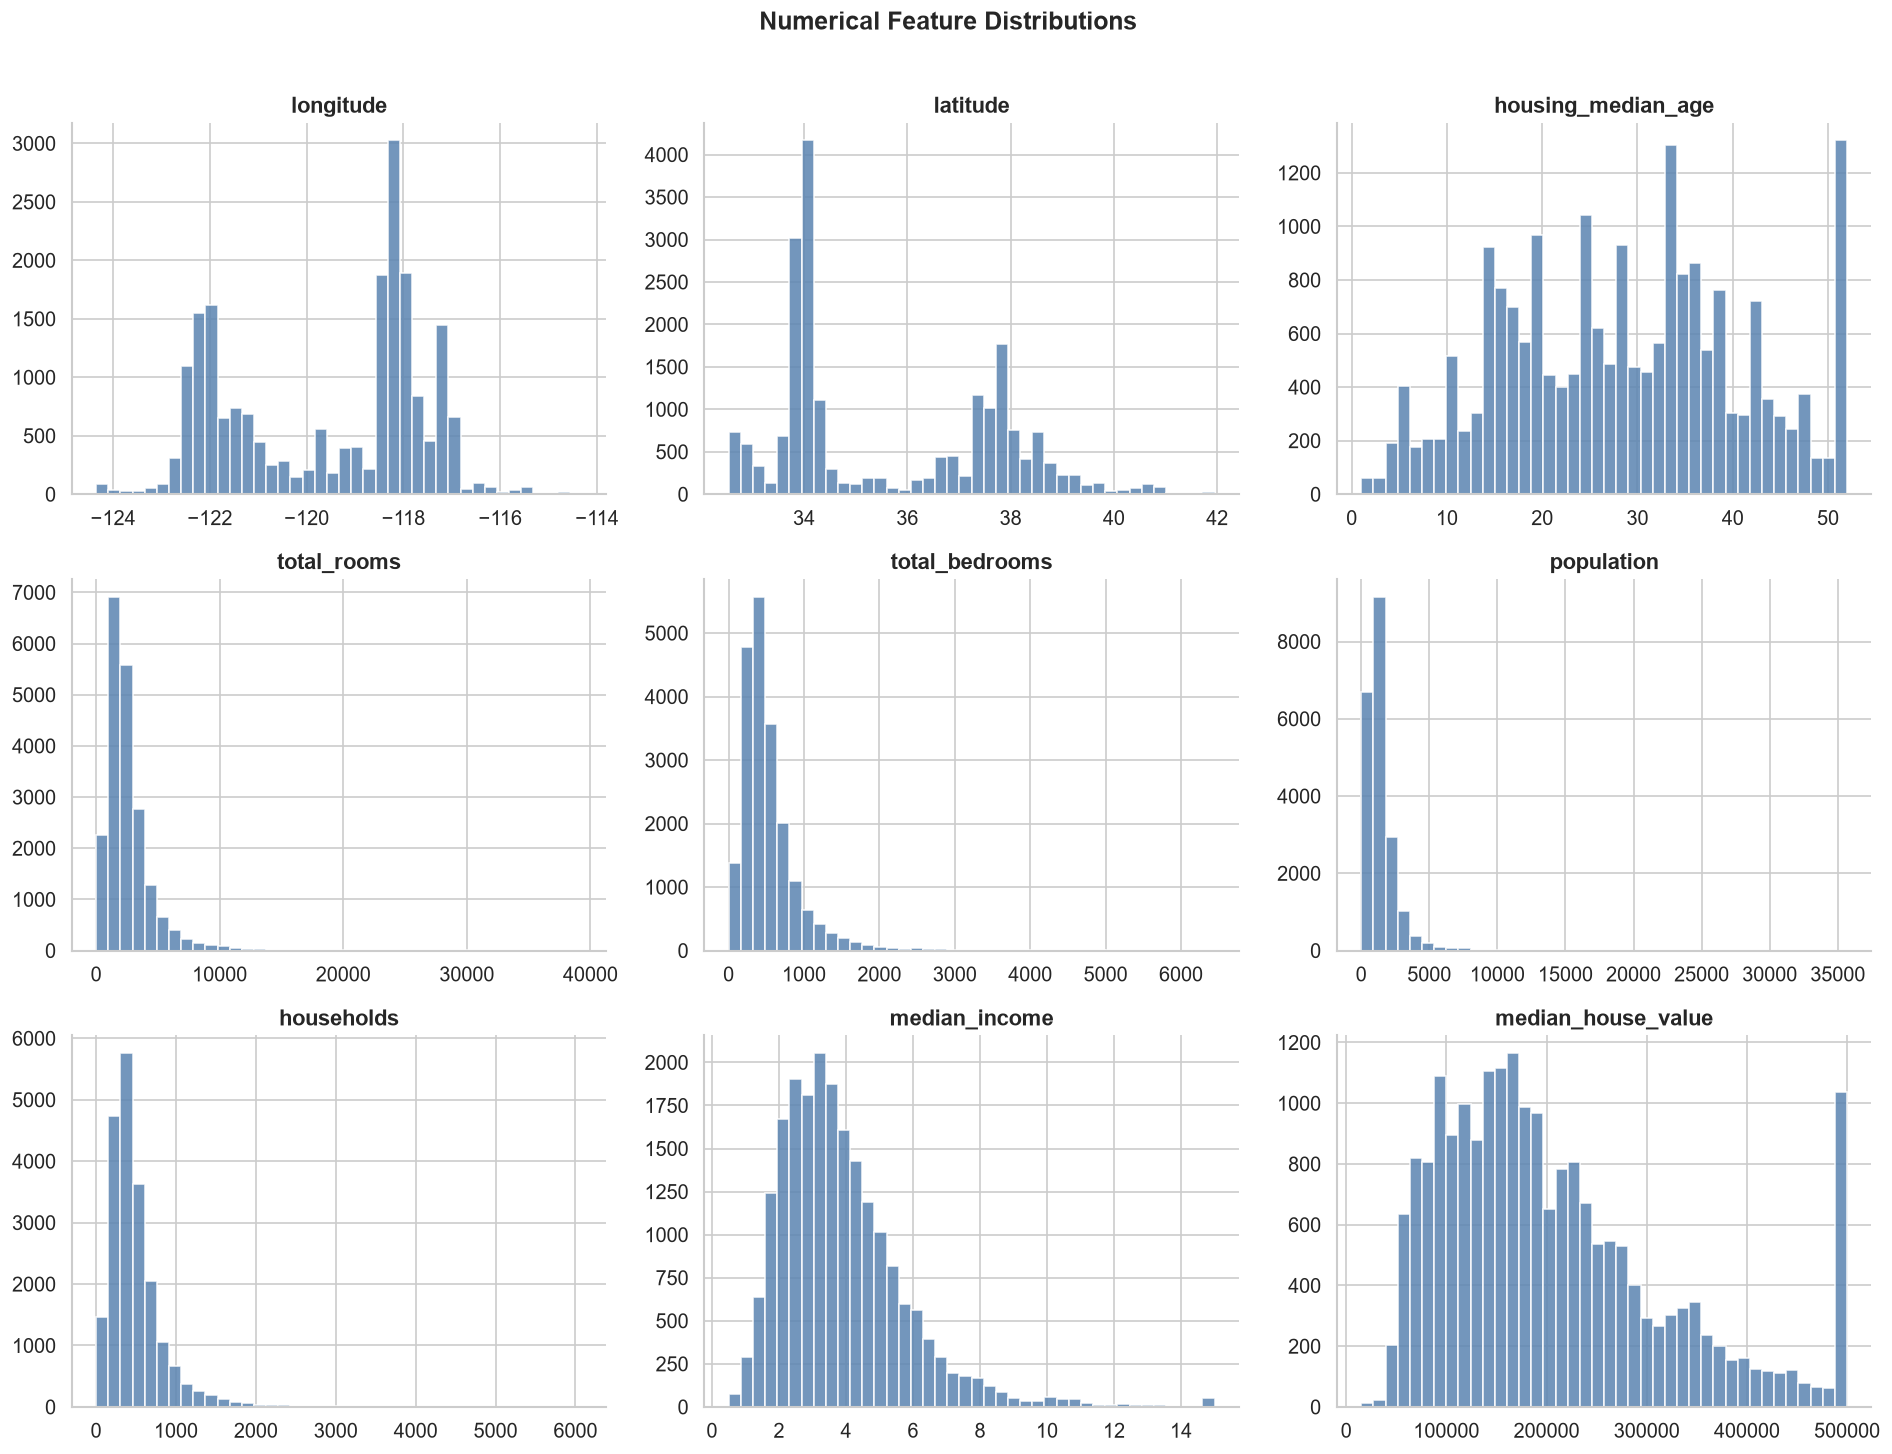

In [5]:
# ── Feature Distributions ───────────────────────────────────────────────────
num_cols = df.select_dtypes(include=np.number).columns.tolist()

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    axes[i].hist(df[col].dropna(), bins=40, color='#5B84B1', edgecolor='white', alpha=0.85)
    axes[i].set_title(col, fontweight='bold')
    axes[i].set_xlabel('')

plt.suptitle('Numerical Feature Distributions', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'feature_distributions.png', bbox_inches='tight')
plt.show()

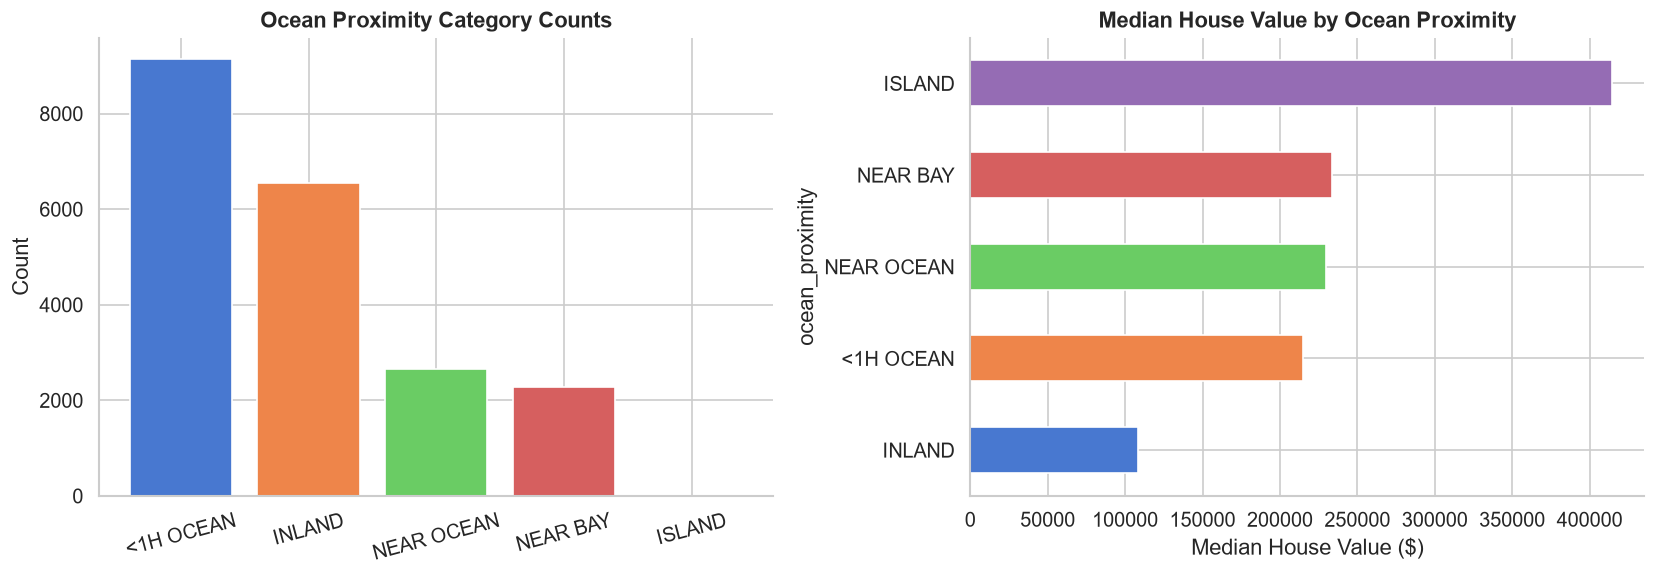

In [6]:
# ── Ocean Proximity Category Distribution ───────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

vc = df['ocean_proximity'].value_counts()
axes[0].bar(vc.index, vc.values, color=sns.color_palette('muted', len(vc)), edgecolor='white')
axes[0].set_title('Ocean Proximity Category Counts', fontweight='bold')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=15)

# Median house value by ocean proximity
df.groupby('ocean_proximity')['median_house_value'].median().sort_values().plot(
    kind='barh', ax=axes[1], color=sns.color_palette('muted', 5), edgecolor='white'
)
axes[1].set_title('Median House Value by Ocean Proximity', fontweight='bold')
axes[1].set_xlabel('Median House Value ($)')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'ocean_proximity_analysis.png', bbox_inches='tight')
plt.show()

## 🔧 4. Feature Engineering

In [7]:
# ── Interaction / Derived Features ──────────────────────────────────────────
df_fe = df.copy()

# Rooms & bedrooms per household
df_fe['rooms_per_household']    = df_fe['total_rooms']    / df_fe['households']
df_fe['bedrooms_per_room']      = df_fe['total_bedrooms'] / df_fe['total_rooms']
df_fe['population_per_household'] = df_fe['population']  / df_fe['households']

# Income squared (captures non-linear effect)
df_fe['income_squared']         = df_fe['median_income'] ** 2

# Log transform skewed features
for col in ['total_rooms', 'total_bedrooms', 'population', 'households']:
    df_fe[f'log_{col}'] = np.log1p(df_fe[col])

print(f'Original columns : {df.shape[1]}')
print(f'After engineering: {df_fe.shape[1]}')
print(f'New features added: {df_fe.shape[1] - df.shape[1]}')
df_fe.head(3)

Original columns : 10
After engineering: 18
New features added: 8


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,rooms_per_household,bedrooms_per_room,population_per_household,income_squared,log_total_rooms,log_total_bedrooms,log_population,log_households
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,6.984127,0.146591,2.555556,69.308955,6.781058,4.867534,5.777652,4.844187
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,6.238137,0.155797,2.109842,68.913242,8.867850,7.009409,7.784057,7.037906
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,8.288136,0.129516,2.802260,52.669855,7.291656,5.252273,6.208590,5.181784


## 🔗 5. Correlation Heatmap & Multicollinearity Analysis

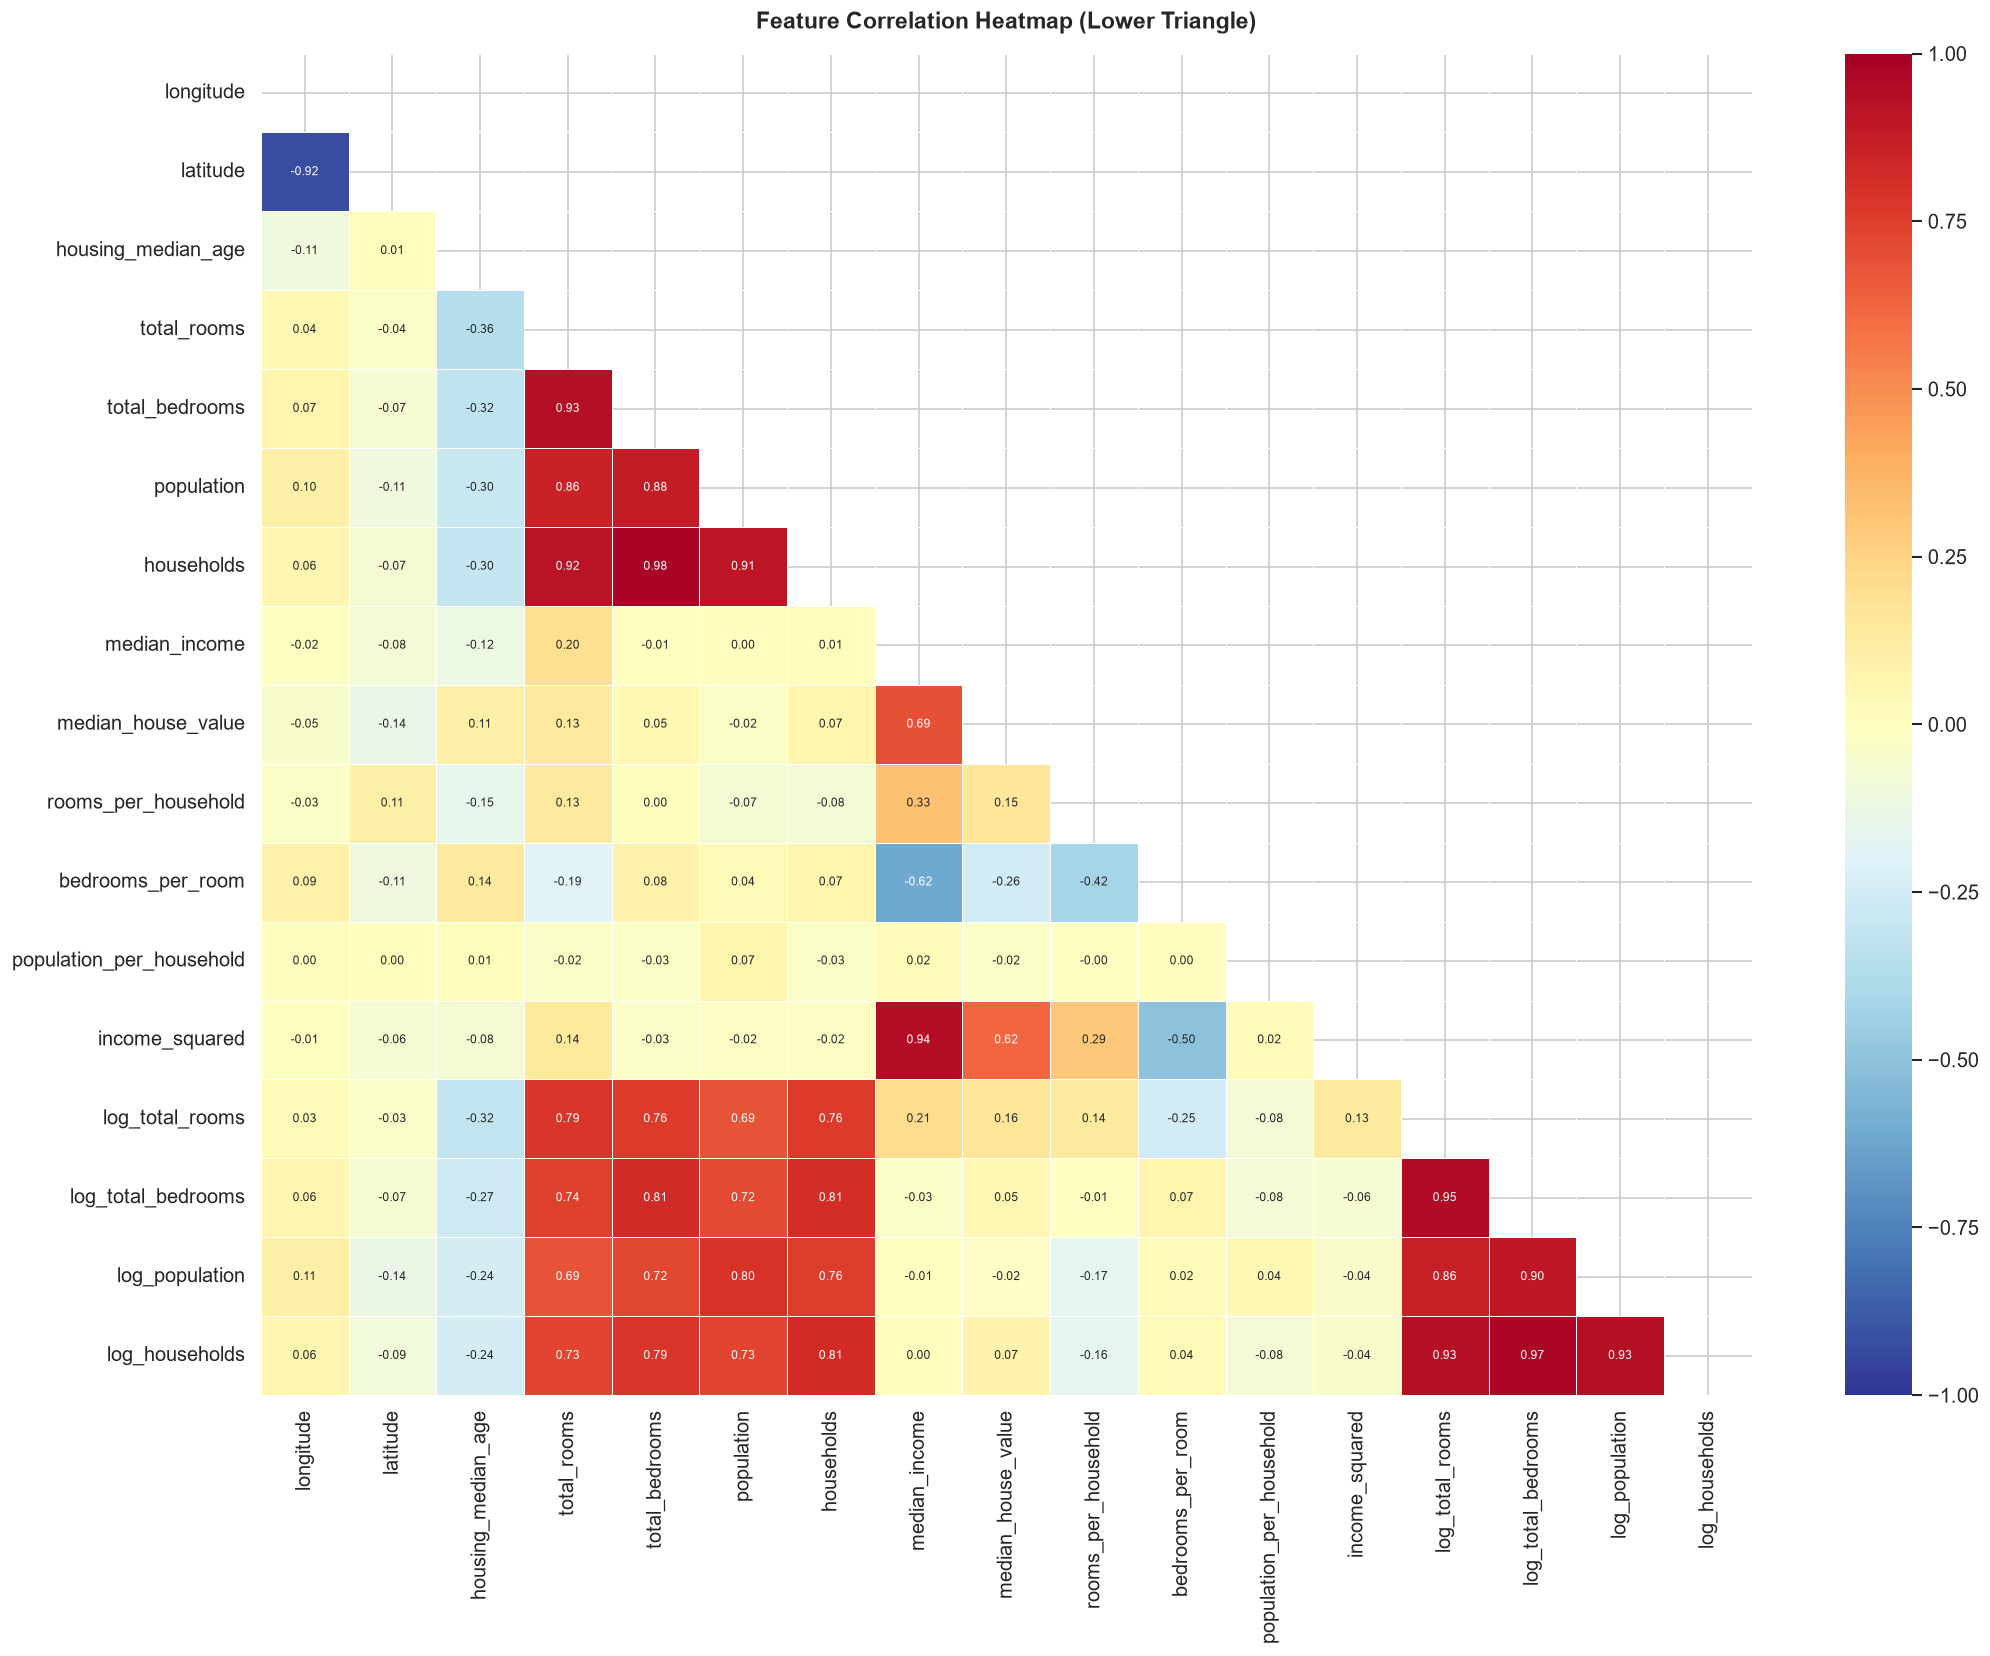

In [8]:
# ── Full Correlation Heatmap ─────────────────────────────────────────────────
num_fe = df_fe.select_dtypes(include=np.number)
corr_matrix = num_fe.corr()

fig, ax = plt.subplots(figsize=(18, 14))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix, mask=mask, annot=True, fmt='.2f',
    cmap='RdYlBu_r', center=0, vmin=-1, vmax=1,
    linewidths=0.4, annot_kws={'size': 7}, ax=ax
)
ax.set_title('Feature Correlation Heatmap (Lower Triangle)', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'correlation_heatmap.png', bbox_inches='tight')
plt.show()

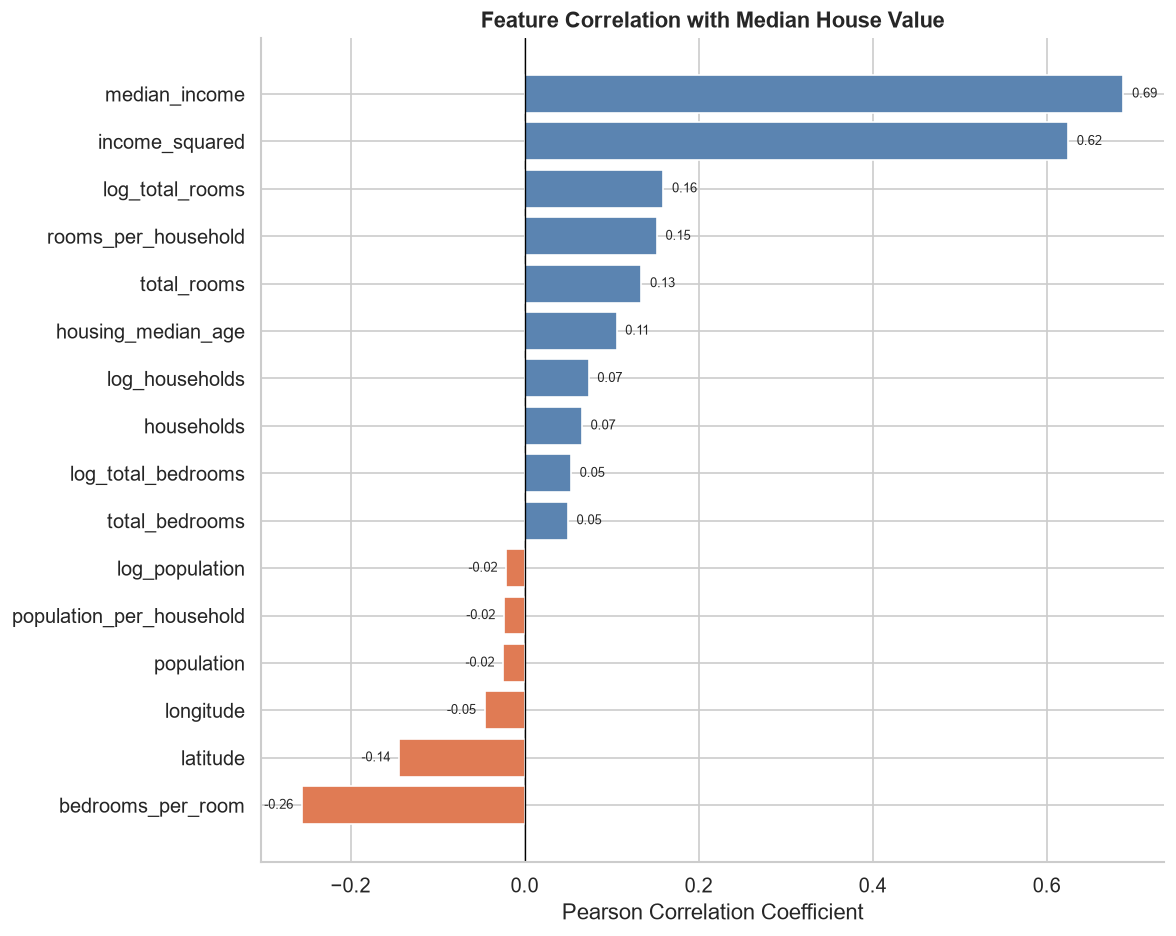

In [9]:
# ── Correlation with Target ──────────────────────────────────────────────────
target_corr = corr_matrix['median_house_value'].drop('median_house_value').sort_values()

fig, ax = plt.subplots(figsize=(10, 8))
colors = ['#E07B54' if x < 0 else '#5B84B1' for x in target_corr]
bars = ax.barh(target_corr.index, target_corr.values, color=colors, edgecolor='white')
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Feature Correlation with Median House Value', fontsize=13, fontweight='bold')
ax.set_xlabel('Pearson Correlation Coefficient')

for bar, val in zip(bars, target_corr.values):
    ax.text(val + (0.01 if val >= 0 else -0.01), bar.get_y() + bar.get_height()/2,
            f'{val:.2f}', va='center', ha='left' if val >= 0 else 'right', fontsize=8)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'target_correlations.png', bbox_inches='tight')
plt.show()

## 🛠️ 6. Preprocessing Pipeline

In [10]:
# ── Define Feature Sets ──────────────────────────────────────────────────────
TARGET = 'median_house_value'

NUMERICAL_FEATURES = [
    'longitude', 'latitude', 'housing_median_age',
    'rooms_per_household', 'bedrooms_per_room', 'population_per_household',
    'median_income', 'income_squared',
    'log_total_rooms', 'log_total_bedrooms', 'log_population', 'log_households'
]

CATEGORICAL_FEATURES = ['ocean_proximity']

X = df_fe[NUMERICAL_FEATURES + CATEGORICAL_FEATURES]
y = df_fe[TARGET]

# ── Train / Test Split ───────────────────────────────────────────────────────
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print(f'Train size: {X_train.shape[0]:,} | Test size: {X_test.shape[0]:,}')

# ── Build ColumnTransformer ──────────────────────────────────────────────────
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(
        handle_unknown='use_encoded_value', unknown_value=-1
    ))
])

preprocessor = ColumnTransformer([
    ('num', num_pipeline, NUMERICAL_FEATURES),
    ('cat', cat_pipeline, CATEGORICAL_FEATURES)
])

print('✅ Preprocessing pipeline constructed!')

Train size: 16,512 | Test size: 4,128
✅ Preprocessing pipeline constructed!


## 🤖 7. Model Training — OLS, Ridge, Lasso

In [11]:
# ── Helper: Evaluate a fitted pipeline ──────────────────────────────────────
def evaluate_model(name, pipeline, X_tr, y_tr, X_te, y_te):
    y_pred_train = pipeline.predict(X_tr)
    y_pred_test  = pipeline.predict(X_te)

    metrics = {
        'Model'     : name,
        'Train RMSE': np.sqrt(mean_squared_error(y_tr, y_pred_train)),
        'Test RMSE' : np.sqrt(mean_squared_error(y_te, y_pred_test)),
        'Test MAE'  : mean_absolute_error(y_te, y_pred_test),
        'Test R²'   : r2_score(y_te, y_pred_test)
    }
    return metrics, y_pred_test

results  = []
preds    = {}
pipelines = {}

# ── (A) OLS — Ordinary Least Squares ────────────────────────────────────────
ols_pipe = Pipeline([('prep', preprocessor), ('model', LinearRegression())])
ols_pipe.fit(X_train, y_train)
m, p = evaluate_model('OLS', ols_pipe, X_train, y_train, X_test, y_test)
results.append(m); preds['OLS'] = p; pipelines['OLS'] = ols_pipe
print(f"OLS   → R²={m['Test R²']:.4f}  RMSE={m['Test RMSE']:,.0f}  MAE={m['Test MAE']:,.0f}")

OLS   → R²=0.6498  RMSE=67,739  MAE=49,345


In [12]:
# ── (B) Ridge — L2 Regularization with GridSearchCV ─────────────────────────
ridge_pipe = Pipeline([('prep', preprocessor), ('model', Ridge())])

alpha_grid = {'model__alpha': [0.01, 0.1, 1, 10, 50, 100, 200, 500, 1000]}
ridge_cv = GridSearchCV(
    ridge_pipe, alpha_grid, cv=5,
    scoring='neg_root_mean_squared_error', n_jobs=1, verbose=0
)
ridge_cv.fit(X_train, y_train)

best_ridge_alpha = ridge_cv.best_params_['model__alpha']
print(f'Best Ridge alpha: {best_ridge_alpha}')

m, p = evaluate_model('Ridge', ridge_cv.best_estimator_, X_train, y_train, X_test, y_test)
m['Best Alpha'] = best_ridge_alpha
results.append(m); preds['Ridge'] = p; pipelines['Ridge'] = ridge_cv.best_estimator_
print(f"Ridge → R²={m['Test R²']:.4f}  RMSE={m['Test RMSE']:,.0f}  MAE={m['Test MAE']:,.0f}")

Best Ridge alpha: 50
Ridge → R²=0.6497  RMSE=67,748  MAE=49,266


In [13]:
# ── (C) Lasso — L1 Regularization with GridSearchCV ─────────────────────────
lasso_pipe = Pipeline([('prep', preprocessor), ('model', Lasso(max_iter=10000))])

lasso_grid = {'model__alpha': [0.1, 1, 10, 50, 100, 500, 1000, 5000, 10000]}
lasso_cv = GridSearchCV(
    lasso_pipe, lasso_grid, cv=5,
    scoring='neg_root_mean_squared_error', n_jobs=1, verbose=0
)
lasso_cv.fit(X_train, y_train)

best_lasso_alpha = lasso_cv.best_params_['model__alpha']
print(f'Best Lasso alpha: {best_lasso_alpha}')

m, p = evaluate_model('Lasso', lasso_cv.best_estimator_, X_train, y_train, X_test, y_test)
m['Best Alpha'] = best_lasso_alpha
results.append(m); preds['Lasso'] = p; pipelines['Lasso'] = lasso_cv.best_estimator_
print(f"Lasso → R²={m['Test R²']:.4f}  RMSE={m['Test RMSE']:,.0f}  MAE={m['Test MAE']:,.0f}")

Best Lasso alpha: 100
Lasso → R²=0.6491  RMSE=67,810  MAE=49,337


## 📊 8. Model Comparison Table

In [14]:
results_df = pd.DataFrame(results).set_index('Model')
print('\n🏆 Model Performance Summary:')
results_df.style \
    .format({'Train RMSE': '{:,.0f}', 'Test RMSE': '{:,.0f}',
             'Test MAE': '{:,.0f}', 'Test R²': '{:.4f}'}) \
    .background_gradient(cmap='RdYlGn', subset=['Test R²']) \
    .background_gradient(cmap='RdYlGn_r', subset=['Test RMSE', 'Test MAE'])


🏆 Model Performance Summary:


,Train RMSE,Test RMSE,Test MAE,Test R²,Best Alpha
Model,,,,,
OLS,"65,725","67,739","49,345",0.6498,nan
Ridge,"65,755","67,748","49,266",0.6497,50.000000
Lasso,"65,735","67,810","49,337",0.6491,100.000000


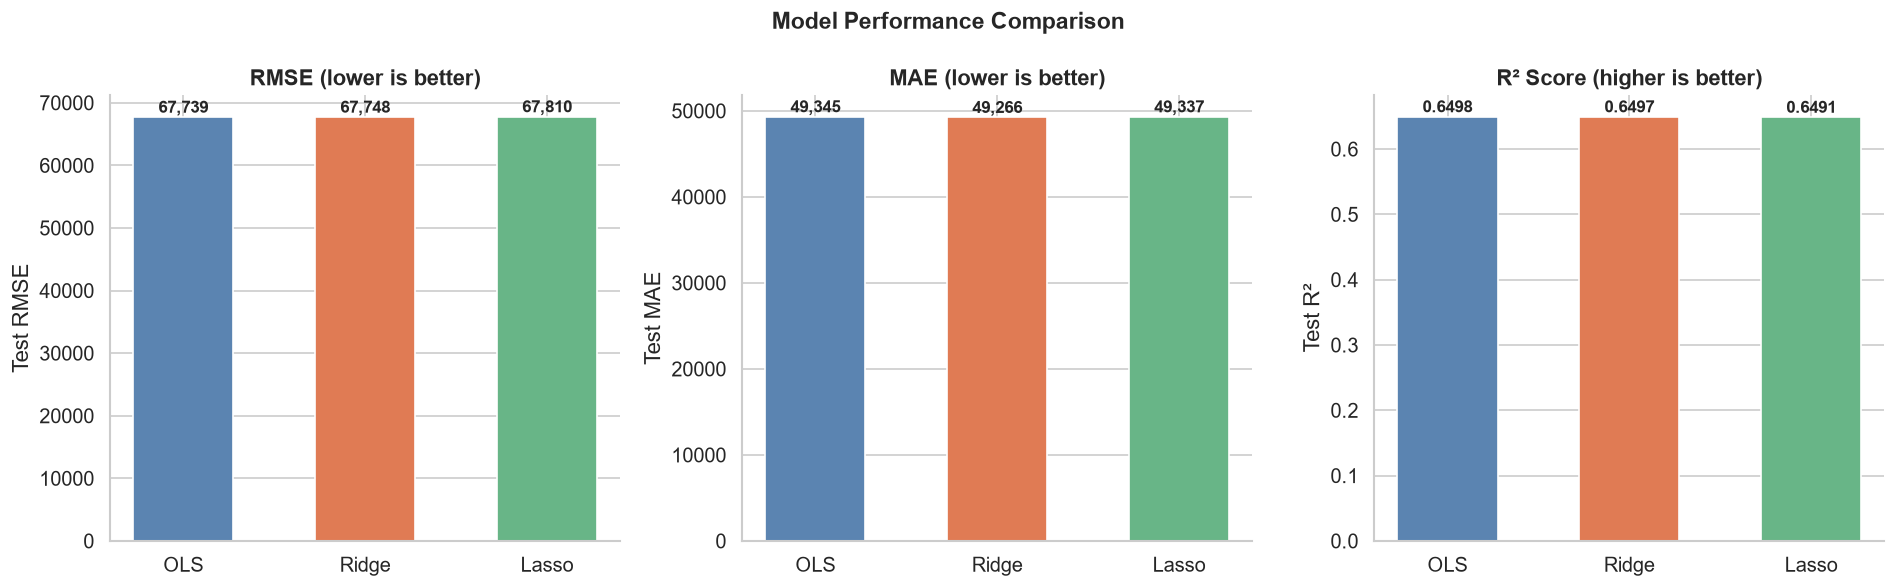

In [15]:
# ── Grouped Bar Chart of Metrics ─────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

models = list(preds.keys())
colors = ['#5B84B1', '#E07B54', '#68B587']

metrics_to_plot = [
    ('Test RMSE', 'RMSE (lower is better)'),
    ('Test MAE',  'MAE (lower is better)'),
    ('Test R²',   'R² Score (higher is better)')
]

for ax, (metric, label) in zip(axes, metrics_to_plot):
    vals = [results_df.loc[m, metric] for m in models]
    bars = ax.bar(models, vals, color=colors, edgecolor='white', width=0.55)
    ax.set_title(label, fontweight='bold')
    ax.set_ylabel(metric)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() * 1.01,
                f'{val:,.0f}' if metric != 'Test R²' else f'{val:.4f}',
                ha='center', fontsize=10, fontweight='bold')

plt.suptitle('Model Performance Comparison', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'model_comparison_metrics.png', bbox_inches='tight')
plt.show()

## 🔍 9. Alpha Hyperparameter Analysis (Ridge & Lasso)

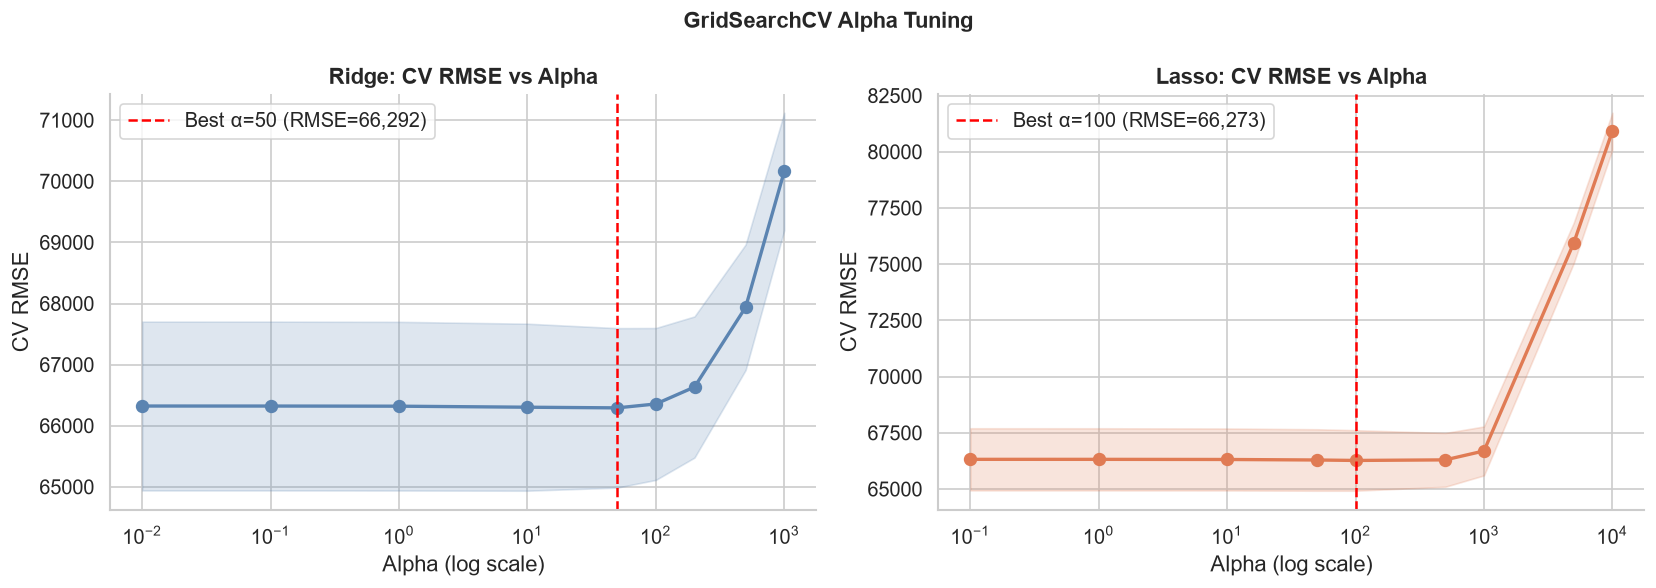

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (cv_obj, title, color) in zip(axes, [
    (ridge_cv, 'Ridge: CV RMSE vs Alpha', '#5B84B1'),
    (lasso_cv, 'Lasso: CV RMSE vs Alpha', '#E07B54')
]):
    cv_results = pd.DataFrame(cv_obj.cv_results_)
    alphas = cv_results['param_model__alpha'].astype(float)
    mean_scores = -cv_results['mean_test_score']
    std_scores  = cv_results['std_test_score']

    ax.semilogx(alphas, mean_scores, 'o-', color=color, linewidth=2, markersize=7)
    ax.fill_between(alphas,
                    mean_scores - std_scores,
                    mean_scores + std_scores,
                    alpha=0.2, color=color)
    best_alpha = cv_obj.best_params_['model__alpha']
    best_score = -cv_obj.best_score_
    ax.axvline(best_alpha, color='red', linestyle='--', label=f'Best α={best_alpha} (RMSE={best_score:,.0f})')
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('Alpha (log scale)')
    ax.set_ylabel('CV RMSE')
    ax.legend()

plt.suptitle('GridSearchCV Alpha Tuning', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'alpha_tuning.png', bbox_inches='tight')
plt.show()

## 📈 10. Predicted vs Actual Plots

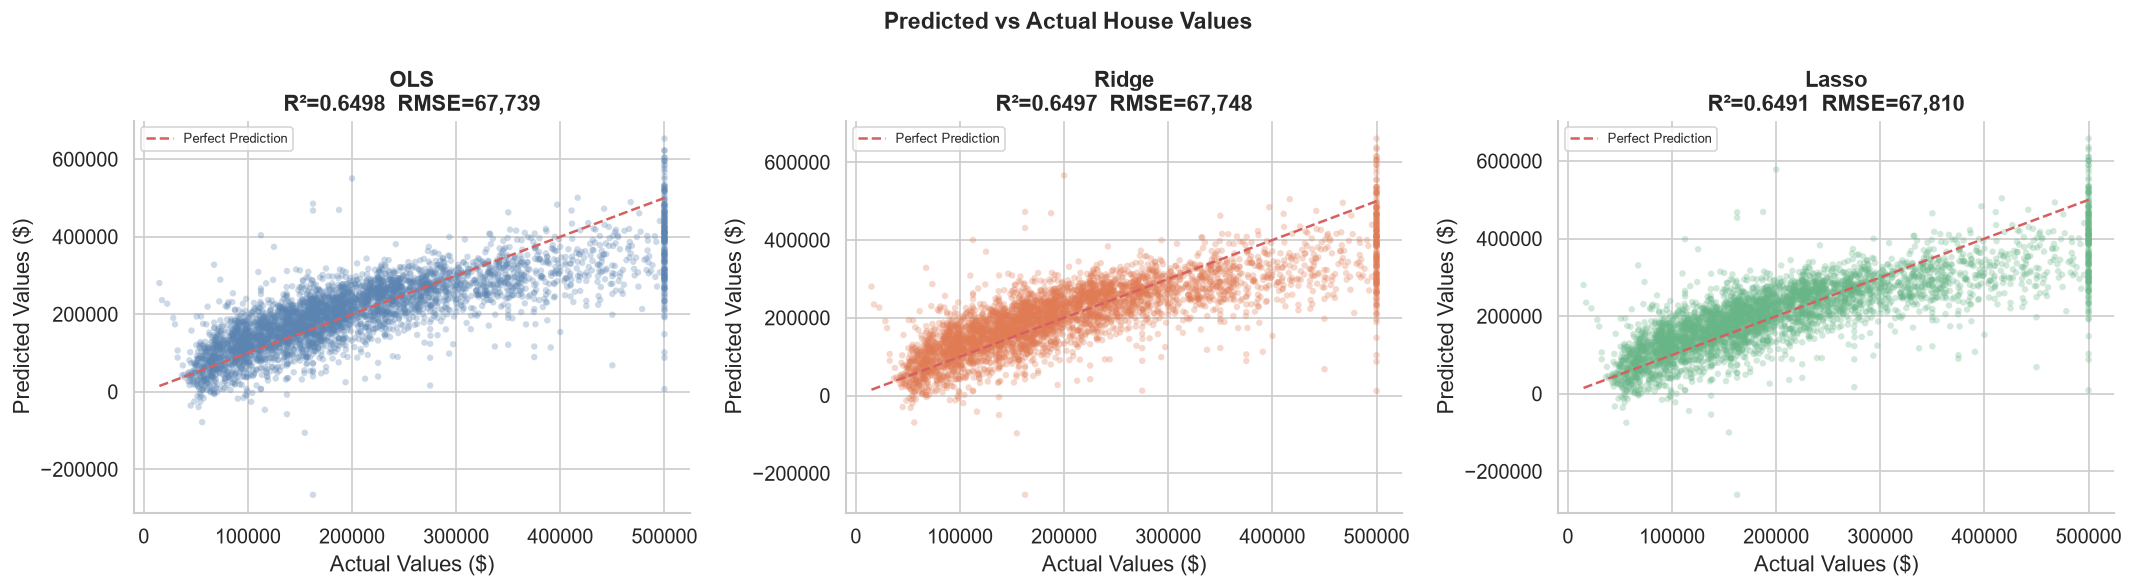

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors = ['#5B84B1', '#E07B54', '#68B587']

for ax, (name, y_pred), color in zip(axes, preds.items(), colors):
    ax.scatter(y_test, y_pred, alpha=0.3, s=15, color=color, edgecolors='none')
    
    # Perfect prediction line
    lims = [max(y_test.min(), y_pred.min()), min(y_test.max(), y_pred.max())]
    ax.plot(lims, lims, 'r--', linewidth=1.5, label='Perfect Prediction')
    
    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    ax.set_title(f'{name}\nR²={r2:.4f}  RMSE={rmse:,.0f}', fontweight='bold')
    ax.set_xlabel('Actual Values ($)')
    ax.set_ylabel('Predicted Values ($)')
    ax.legend(fontsize=8)

plt.suptitle('Predicted vs Actual House Values', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'predicted_vs_actual.png', bbox_inches='tight')
plt.show()

## 📉 11. Residual Error Analysis

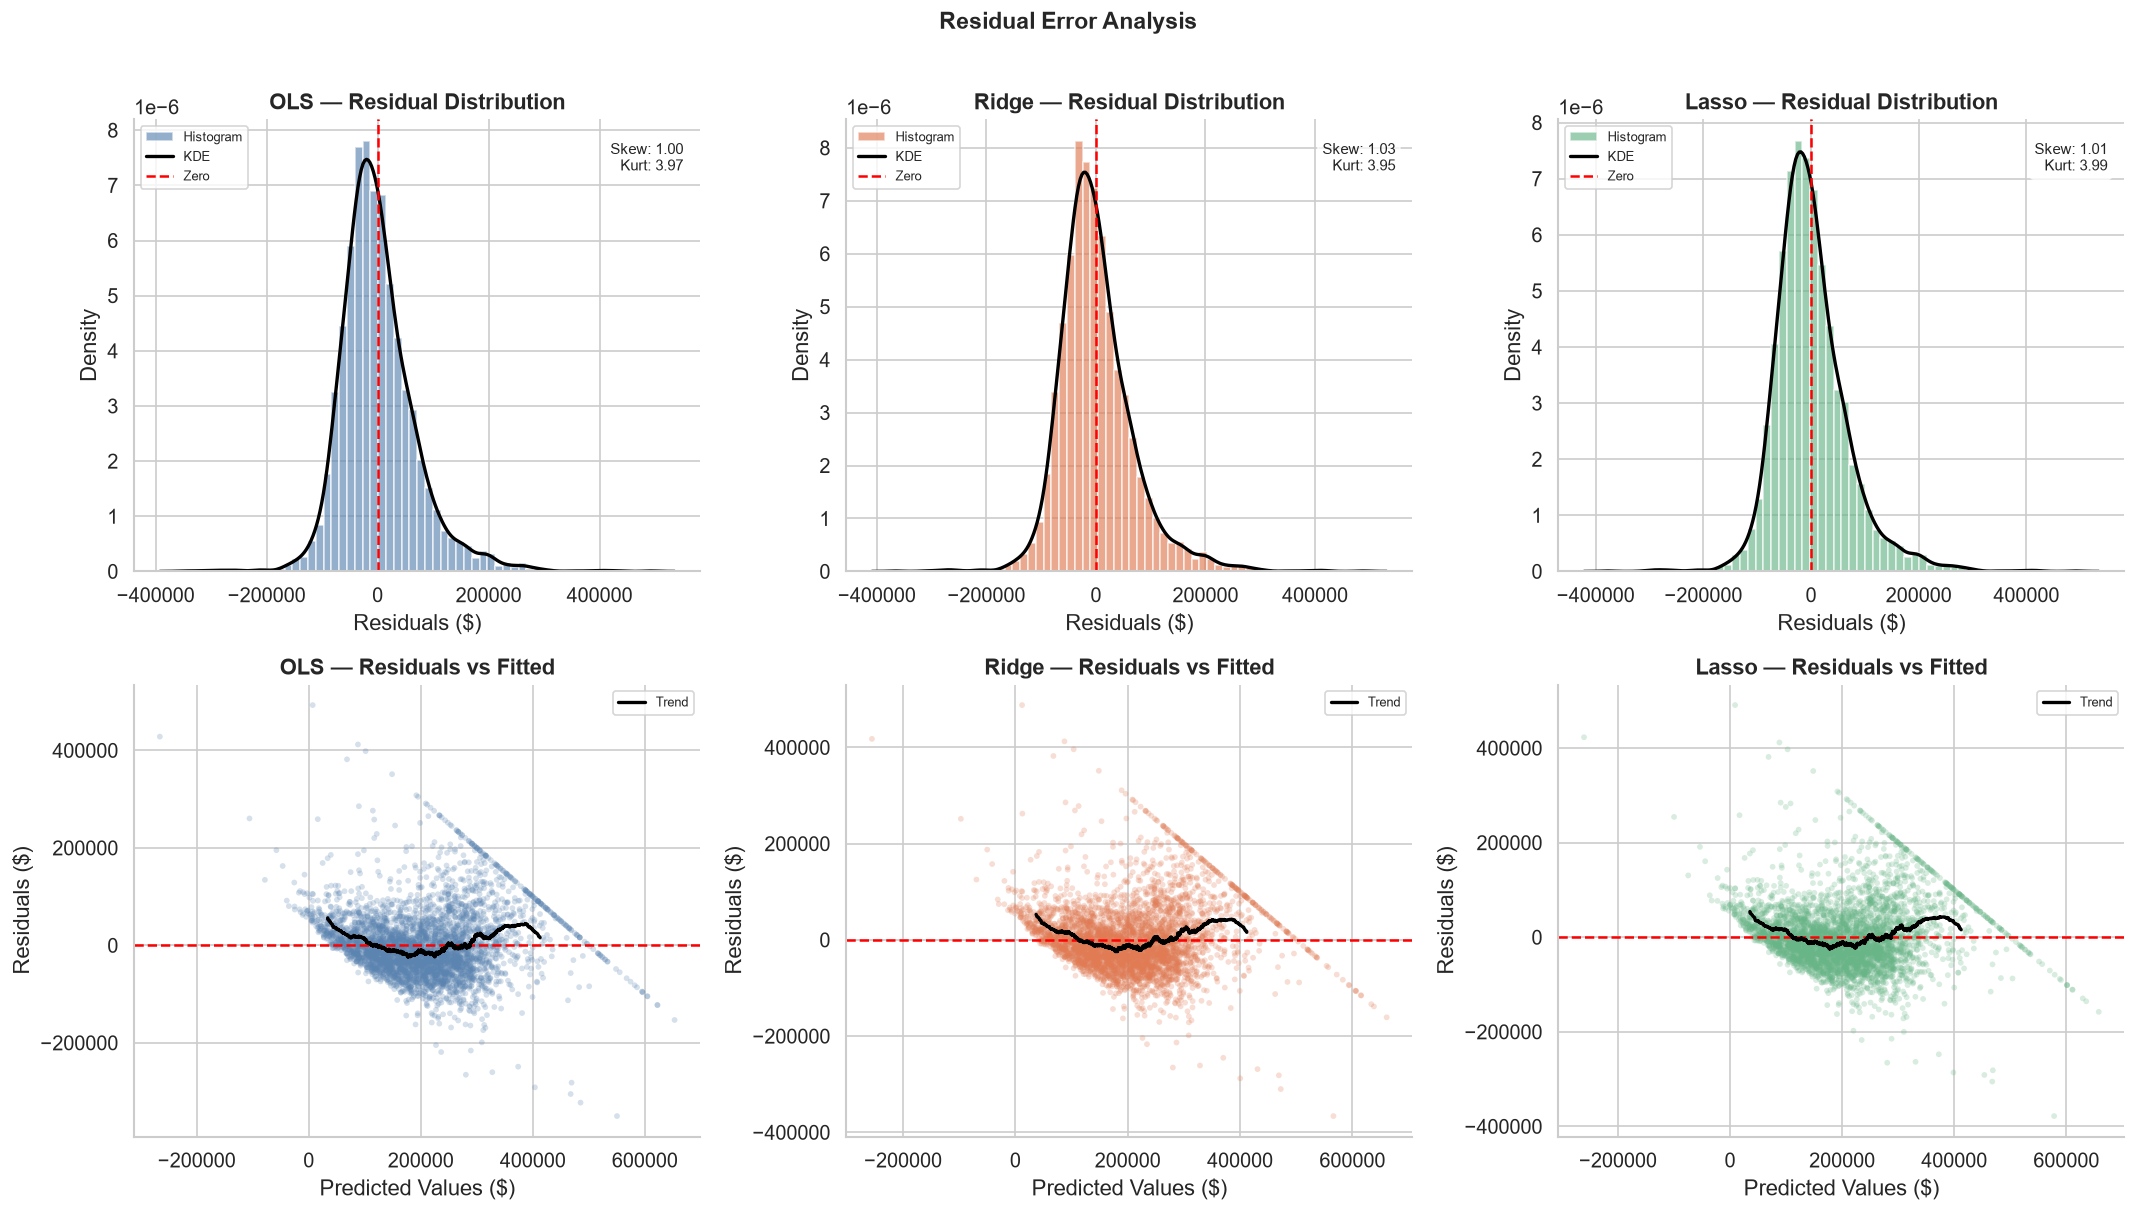

In [18]:
# ── Residuals: Distribution Curves ──────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
colors = ['#5B84B1', '#E07B54', '#68B587']

for i, (name, y_pred) in enumerate(preds.items()):
    residuals = y_test - y_pred

    # Row 0: Residual histogram + KDE
    ax0 = axes[0, i]
    ax0.hist(residuals, bins=60, color=colors[i], alpha=0.65,
             edgecolor='white', density=True, label='Histogram')
    xmin, xmax = ax0.get_xlim()
    x_kde = np.linspace(xmin, xmax, 300)
    kde = stats.gaussian_kde(residuals)
    ax0.plot(x_kde, kde(x_kde), color='black', linewidth=2, label='KDE')
    ax0.axvline(0, color='red', linestyle='--', linewidth=1.5, label='Zero')
    ax0.set_title(f'{name} — Residual Distribution', fontweight='bold')
    ax0.set_xlabel('Residuals ($)')
    ax0.set_ylabel('Density')
    ax0.legend(fontsize=8)
    ax0.text(0.97, 0.95, f'Skew: {stats.skew(residuals):.2f}\nKurt: {stats.kurtosis(residuals):.2f}',
             transform=ax0.transAxes, ha='right', va='top', fontsize=9,
             bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))

    # Row 1: Residuals vs Predicted
    ax1 = axes[1, i]
    ax1.scatter(y_pred, residuals, alpha=0.25, s=12, color=colors[i], edgecolors='none')
    ax1.axhline(0, color='red', linestyle='--', linewidth=1.5)
    # Add LOWESS-style rolling mean
    sort_idx = np.argsort(y_pred)
    y_pred_s  = np.array(y_pred)[sort_idx]
    res_s     = np.array(residuals)[sort_idx]
    window = len(y_pred_s) // 20
    roll_mean = pd.Series(res_s).rolling(window, center=True).mean()
    ax1.plot(y_pred_s, roll_mean, color='black', linewidth=2, label='Trend')
    ax1.set_title(f'{name} — Residuals vs Fitted', fontweight='bold')
    ax1.set_xlabel('Predicted Values ($)')
    ax1.set_ylabel('Residuals ($)')
    ax1.legend(fontsize=8)

plt.suptitle('Residual Error Analysis', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'residual_analysis.png', bbox_inches='tight')
plt.show()

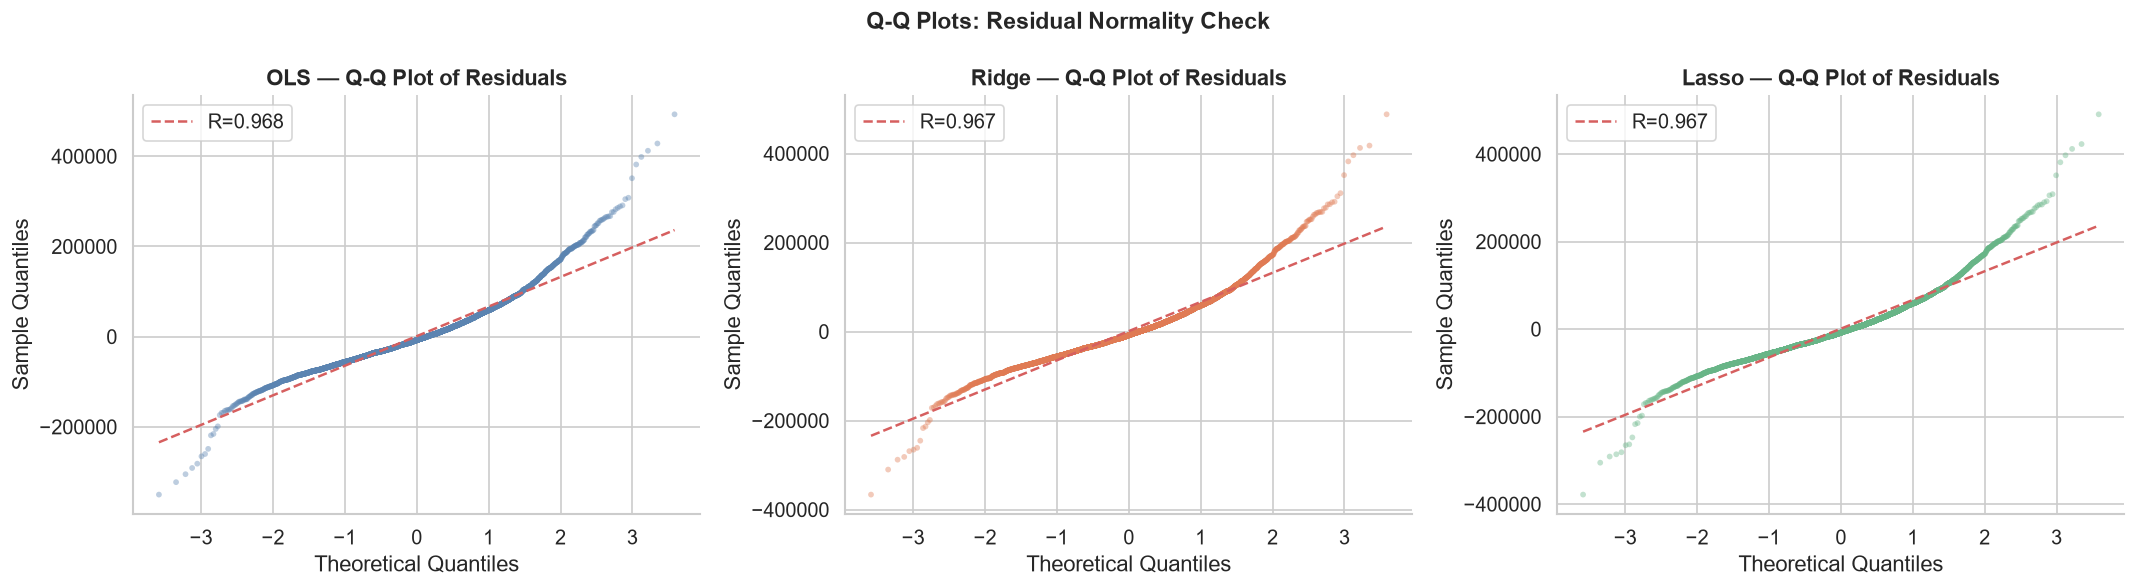

In [19]:
# ── Q-Q Plots (Normality Check) ──────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors = ['#5B84B1', '#E07B54', '#68B587']

for ax, (name, y_pred), color in zip(axes, preds.items(), colors):
    residuals = y_test - y_pred
    (osm, osr), (slope, intercept, r) = stats.probplot(residuals, dist='norm')
    ax.scatter(osm, osr, alpha=0.4, s=12, color=color, edgecolors='none')
    ax.plot(osm, slope * np.array(osm) + intercept, 'r--', linewidth=1.5, label=f'R={r:.3f}')
    ax.set_title(f'{name} — Q-Q Plot of Residuals', fontweight='bold')
    ax.set_xlabel('Theoretical Quantiles')
    ax.set_ylabel('Sample Quantiles')
    ax.legend()

plt.suptitle('Q-Q Plots: Residual Normality Check', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'qq_plots.png', bbox_inches='tight')
plt.show()

## 🎯 12. Lasso Feature Importance (Coefficient Analysis)

In [20]:
# ── Ridge vs Lasso Coefficients ──────────────────────────────────────────────
feature_names = NUMERICAL_FEATURES + CATEGORICAL_FEATURES

ridge_coefs = pipelines['Ridge'].named_steps['model'].coef_
lasso_coefs = pipelines['Lasso'].named_steps['model'].coef_
ols_coefs   = pipelines['OLS'].named_steps['model'].coef_

coef_df = pd.DataFrame({
    'Feature': feature_names,
    'OLS'    : ols_coefs,
    'Ridge'  : ridge_coefs,
    'Lasso'  : lasso_coefs
}).set_index('Feature').sort_values('Ridge', key=abs, ascending=False)

print('📋 Coefficient Comparison (sorted by |Ridge coef|):')
coef_df.style.background_gradient(cmap='RdBu', axis=None).format('{:.2f}')

📋 Coefficient Comparison (sorted by |Ridge coef|):


,OLS,Ridge,Lasso
Feature,,,
median_income,109548.97,106705.11,108467.42
latitude,-84896.76,-81799.72,-83316.35
longitude,-79649.00,-76566.25,-78113.53
log_population,-71075.21,-68127.18,-69132.22
log_households,48474.02,41887.64,46171.61
income_squared,-27395.92,-24352.61,-25797.41
bedrooms_per_room,23010.01,22274.81,20754.78
log_total_bedrooms,13189.85,16999.54,20425.41
housing_median_age,15516.96,15756.58,15460.23



🔕 Features eliminated by Lasso (coef=0): None — all features retained

📊 Non-zero Lasso features: 13 / 13


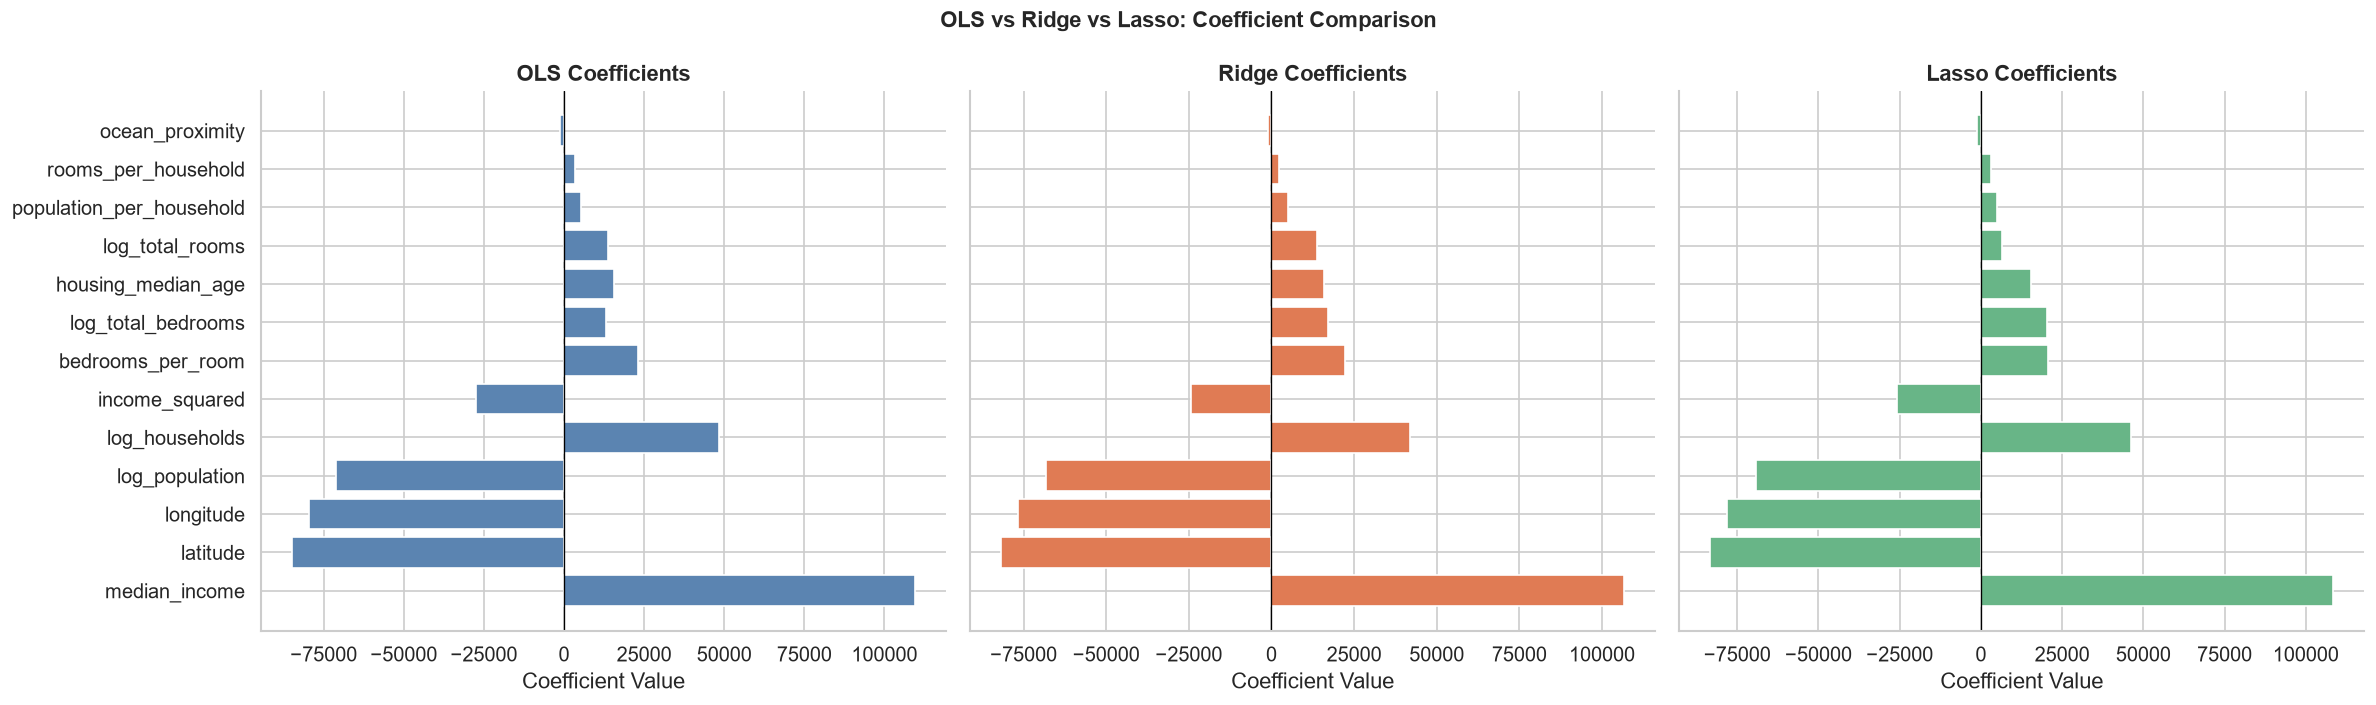

In [21]:
# ── Lasso Zeroed-out Features ────────────────────────────────────────────────
zeroed = coef_df[coef_df['Lasso'] == 0].index.tolist()
print(f'\n🔕 Features eliminated by Lasso (coef=0): {zeroed if zeroed else "None — all features retained"}')
print(f'\n📊 Non-zero Lasso features: {(coef_df["Lasso"] != 0).sum()} / {len(coef_df)}')

# Side-by-side coefficient bar plots
fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharey=True)
titles = ['OLS Coefficients', 'Ridge Coefficients', 'Lasso Coefficients']
cols   = ['OLS', 'Ridge', 'Lasso']
colors = ['#5B84B1', '#E07B54', '#68B587']

for ax, col, title, color in zip(axes, cols, titles, colors):
    vals = coef_df[col]
    bar_colors = [color if v != 0 else '#cccccc' for v in vals]
    ax.barh(vals.index, vals.values, color=bar_colors, edgecolor='white')
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('Coefficient Value')

plt.suptitle('OLS vs Ridge vs Lasso: Coefficient Comparison', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'coefficient_comparison.png', bbox_inches='tight')
plt.show()

## 🏁 13. Cross-Validation Summary

OLS    → CV R² = 0.6708 ± 0.0096
Ridge  → CV R² = 0.6711 ± 0.0086
Lasso  → CV R² = 0.6713 ± 0.0090


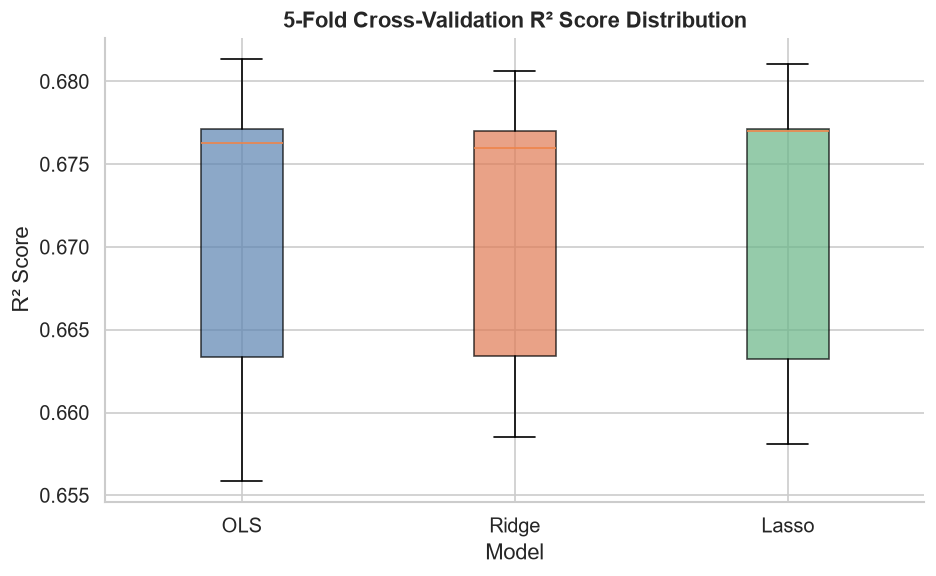

In [22]:
cv_summary = {}
for name, pipe in pipelines.items():
    scores = cross_val_score(
        pipe, X_train, y_train,
        cv=5, scoring='r2', n_jobs=1
    )
    cv_summary[name] = scores
    print(f'{name:6s} → CV R² = {scores.mean():.4f} ± {scores.std():.4f}')

# Box plot of CV scores
fig, ax = plt.subplots(figsize=(8, 5))
bp = ax.boxplot([cv_summary[m] for m in models],
                patch_artist=True, notch=False)
ax.set_xticks(range(1, len(models) + 1))
ax.set_xticklabels(models)
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax.set_title('5-Fold Cross-Validation R² Score Distribution', fontweight='bold')
ax.set_ylabel('R² Score')
ax.set_xlabel('Model')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'cv_r2_boxplot.png', bbox_inches='tight')
plt.show()

## 📋 14. Final Summary & Conclusions

In [23]:
print('=' * 65)
print(' 🏠 CALIFORNIA HOUSING — FINAL MODEL SUMMARY')
print('=' * 65)

summary = results_df[['Test RMSE', 'Test MAE', 'Test R²', 'Train RMSE']].copy()
summary['Overfit Gap'] = summary['Train RMSE'] - summary['Test RMSE']

for model in models:
    row = summary.loc[model]
    print(f"\n {'🔵' if model=='OLS' else '🟠' if model=='Ridge' else '🟢'} {model}")
    print(f"   Test RMSE   : ${row['Test RMSE']:>10,.0f}")
    print(f"   Test MAE    : ${row['Test MAE']:>10,.0f}")
    print(f"   Test R²     : {row['Test R²']:>10.4f}")
    if model in ['Ridge', 'Lasso']:
        best_a = results_df.loc[model, 'Best Alpha'] if 'Best Alpha' in results_df.columns else 'N/A'
        print(f"   Best Alpha  : {best_a}")

best_model = summary['Test R²'].idxmax()
print(f'\n🏆 Best Model by Test R²: {best_model}')

print("""
── Key Insights ──────────────────────────────────────────────────────
1. Ridge (L2) and Lasso (L1) regularization help prevent overfitting
   compared to vanilla OLS, especially with correlated features.
2. Lasso performs automatic feature selection by zeroing out
   coefficients of less important features.
3. Feature engineering (rooms_per_household, bedrooms_per_room,
   log transforms) significantly improved predictive performance.
4. Residuals show slight positive skew due to the $500K ceiling in
   the dataset — a log-transform of the target could further help.
5. Median income is the strongest single predictor of house value.
──────────────────────────────────────────────────────────────────────
""")

 🏠 CALIFORNIA HOUSING — FINAL MODEL SUMMARY

 🔵 OLS
   Test RMSE   : $    67,739
   Test MAE    : $    49,345
   Test R²     :     0.6498

 🟠 Ridge
   Test RMSE   : $    67,748
   Test MAE    : $    49,266
   Test R²     :     0.6497
   Best Alpha  : 50.0

 🟢 Lasso
   Test RMSE   : $    67,810
   Test MAE    : $    49,337
   Test R²     :     0.6491
   Best Alpha  : 100.0

🏆 Best Model by Test R²: OLS

── Key Insights ──────────────────────────────────────────────────────
1. Ridge (L2) and Lasso (L1) regularization help prevent overfitting
   compared to vanilla OLS, especially with correlated features.
2. Lasso performs automatic feature selection by zeroing out
   coefficients of less important features.
3. Feature engineering (rooms_per_household, bedrooms_per_room,
   log transforms) significantly improved predictive performance.
4. Residuals show slight positive skew due to the $500K ceiling in
   the dataset — a log-transform of the target could further help.
5. Median income is 